# 107_03 — Convergencia de las cadenas MCMC · BTCUSDT (Binance) horario · log volatilidad realizada · **barrido en $M$**

Paso **3a** del ciclo. Este notebook **sólo diagnostica las cadenas**: no
predice, no evalúa y no toca el bloque de prueba. Si algo aquí falla, los
números de `107_04` no significan nada, y por eso son notebooks separados.

Los cálculos viven en `fit/convergencia_barrido.py` y las figuras en
`graphics/viz_convergencia.py`; este notebook los orquesta.

Covariables cruzadas con un solo rezago ($p=M$): el diseño cambia con $M$, así que MATLAB entrena **cada** $M$ y `hyperparameters.json["trazas_en"]` apunta al propio punto. Datos reales: no hay generador contra el cual contrastar la selección (§6).

| Estadístico | Referencia | Lectura |
|---|---|---|
| ESS | Geyer (1992) | $\gtrsim 400$ ideal, $>100$ aceptable |
| Geweke $z$ | test $z$ entre segmentos | $\lvert z\rvert < 2$ ⇒ no se rechaza |
| $\hat R$ | Gelman-Rubin | $< 1.1$ ⇒ convergencia |

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, diagnosticar_punto, imprimir_convergencia,
    ocupacion_mezcla, diagnostico_gating, pip_punto,
    verificar_muestreador_predictor, diagnostico_paso_gamma,
    tabla_barrido, ocupacion_barrido, pip_barrido, veredicto_barrido,
)
from model_psbp_fd.graphics import (
    plot_global_components, plot_active_clusters,
    plot_convergence_bj, plot_convergence_pj,
    plot_ocupacion_mezcla, plot_gating, plot_diagnostico_vs_M,
    plot_ocupacion_vs_M, plot_pip_vs_M,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 107_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "btc_107", 1   # ventana 1: 2020-01-01 .. 2026-08-31, 70/30 (107_01 §1.1)
M_FPCA_LIST = (10,)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None

# Propias de la convergencia.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
BURN_EVAL           = None    # iteraciones descartadas; None = el burn del .mat
SD_PIP_MAX          = 0.15    # dispersión entre cadenas que se avisa
CORR_MIN_CONTRATO   = 0.999   # corr(inEout, predict) mínima, §7

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
# Salidas que CRUZAN los M: directorio hermano de los de cada punto.
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 80-83)")


EXPERIMENT_BASE : real_btc_107_v01
barrido en M    : [10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_btc_107_v01_barrido_M   (archivos 80-83)


In [3]:
# EST[M] es el estado completo de cada punto; todo lo que sigue lo consume por índice.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST, PROJECT_ROOT,
                                  dominio=DOMINIO)

  M  comp  cadenas  covariables  seed_base
 10    10        1           10  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)


## 2. Lectura de las trazas

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS, BURN_EVAL)   # los M efectivamente disponibles

OK M=10: 10 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente


## 3. Tabla de diagnósticos

ESS, Geweke y $\hat R$ **sin generar figuras**. Una tabla por $M$, guardada en el
directorio de su punto (`40_diagnosticos_mcmc.csv`); la comparación entre $M$ va
en §8.

In [5]:
for M in M_OK:
    diag_df = diagnosticar_punto(EST[M])
    display(diag_df.style
        .format({"ess_min": "{:.1f}", "ess_mean": "{:.1f}",
                 "geweke_max": "{:+.2f}", "rhat": "{:.4f}"})
        .background_gradient(subset=["rhat"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption(f"M={M} - diagnósticos MCMC por componente FPCA y variable"))

imprimir_convergencia(EST, M_OK)

[tabla_diagnosticos] inicio (200 pasos)


  1/200 ( 0.5%) t=0.0s eta=1.1s  fpc_1 beta_j[fpc_1_lag1] rhat=nan ess_min=1439


  10/200 ( 5.0%) t=0.0s eta=0.2s  fpc_1 beta_j[fpc_10_lag1] rhat=nan ess_min=1715


  20/200 (10.0%) t=0.0s eta=0.1s  fpc_1 p_j[fpc_10_lag1] rhat=nan ess_min=113


  30/200 (15.0%) t=0.0s eta=0.1s  fpc_2 beta_j[fpc_10_lag1] rhat=nan ess_min=1759


  40/200 (20.0%) t=0.0s eta=0.1s  fpc_2 p_j[fpc_10_lag1] rhat=nan ess_min=291


  50/200 (25.0%) t=0.0s eta=0.1s  fpc_3 beta_j[fpc_10_lag1] rhat=nan ess_min=1666


  60/200 (30.0%) t=0.0s eta=0.1s  fpc_3 p_j[fpc_10_lag1] rhat=nan ess_min=108


  70/200 (35.0%) t=0.0s eta=0.1s  fpc_4 beta_j[fpc_10_lag1] rhat=nan ess_min=1865


  80/200 (40.0%) t=0.0s eta=0.1s  fpc_4 p_j[fpc_10_lag1] rhat=nan ess_min=178


  90/200 (45.0%) t=0.0s eta=0.1s  fpc_5 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  100/200 (50.0%) t=0.0s eta=0.0s  fpc_5 p_j[fpc_10_lag1] rhat=nan ess_min=82


  110/200 (55.0%) t=0.1s eta=0.0s  fpc_6 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  120/200 (60.0%) t=0.1s eta=0.0s  fpc_6 p_j[fpc_10_lag1] rhat=nan ess_min=136


  130/200 (65.0%) t=0.1s eta=0.0s  fpc_7 beta_j[fpc_10_lag1] rhat=nan ess_min=589


  140/200 (70.0%) t=0.1s eta=0.0s  fpc_7 p_j[fpc_10_lag1] rhat=nan ess_min=213


  150/200 (75.0%) t=0.1s eta=0.0s  fpc_8 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  160/200 (80.0%) t=0.1s eta=0.0s  fpc_8 p_j[fpc_10_lag1] rhat=nan ess_min=310


  170/200 (85.0%) t=0.1s eta=0.0s  fpc_9 beta_j[fpc_10_lag1] rhat=nan ess_min=1808


  180/200 (90.0%) t=0.1s eta=0.0s  fpc_9 p_j[fpc_10_lag1] rhat=nan ess_min=233


  190/200 (95.0%) t=0.1s eta=0.0s  fpc_10 beta_j[fpc_10_lag1] rhat=nan ess_min=1581


  200/200 (100.0%) t=0.1s eta=0.0s  fpc_10 p_j[fpc_10_lag1] rhat=nan ess_min=196


[tabla_diagnosticos] listo: 200 pasos en 0.1s  53 variables sin converger de 200


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\fit\diagnostics_mcmc.py:269: RuntimeWarning: All-NaN axis encountered
  "rhat_max":        float(np.nanmax(tabla["rhat"])),


,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,1,2000,1438.5,1438.5,+1.15,nan,True
1,1,beta_j,fpc_2_lag1,1,2000,1537.8,1537.8,+1.75,nan,True
2,1,beta_j,fpc_3_lag1,1,2000,1616.7,1616.7,+1.31,nan,True
3,1,beta_j,fpc_4_lag1,1,2000,2000.0,2000.0,+0.73,nan,True
4,1,beta_j,fpc_5_lag1,1,2000,1811.2,1811.2,+1.35,nan,True
5,1,beta_j,fpc_6_lag1,1,2000,2000.0,2000.0,+1.00,nan,True
6,1,beta_j,fpc_7_lag1,1,2000,2000.0,2000.0,+1.41,nan,True
7,1,beta_j,fpc_8_lag1,1,2000,1786.9,1786.9,+1.05,nan,True
8,1,beta_j,fpc_9_lag1,1,2000,1762.8,1762.8,+1.34,nan,True
9,1,beta_j,fpc_10_lag1,1,2000,1715.5,1715.5,+0.06,nan,True


  M = 10   (real_btc_107_v01_m10)
  Rhat max nan (umbral 1.1)  ·  ESS min 5.5 (umbral 100.0)  ·  |Geweke| max 12.41 (umbral 2.0)
  variables sin converger: 53 de 200   VEREDICTO: X REVISAR
    · FPC 1 p_j fpc_4_lag1: Rhat=nan ESS=101 G=+4.58
    · FPC 1 p_j fpc_5_lag1: Rhat=nan ESS=17 G=+1.14
    · FPC 1 p_j fpc_8_lag1: Rhat=nan ESS=113 G=+2.53
    · FPC 1 p_j fpc_9_lag1: Rhat=nan ESS=58 G=+2.63
    · FPC 2 beta_j fpc_1_lag1: Rhat=nan ESS=1451 G=+2.41
    · FPC 2 beta_j fpc_4_lag1: Rhat=nan ESS=44 G=+3.92
    · FPC 2 p_j fpc_1_lag1: Rhat=nan ESS=14 G=+6.03
    · FPC 2 p_j fpc_2_lag1: Rhat=nan ESS=140 G=+3.49
    · FPC 2 p_j fpc_3_lag1: Rhat=nan ESS=134 G=+4.29
    · FPC 2 p_j fpc_4_lag1: Rhat=nan ESS=6 G=+4.75
    · FPC 2 p_j fpc_5_lag1: Rhat=nan ESS=214 G=+3.01
    · FPC 2 p_j fpc_6_lag1: Rhat=nan ESS=198 G=+3.19
    · FPC 2 p_j fpc_8_lag1: Rhat=nan ESS=119 G=+2.47
    · FPC 2 p_j fpc_9_lag1: Rhat=nan ESS=230 G=+2.83
    · FPC 3 beta_j fpc_1_lag1: Rhat=nan ESS=1634 G=+4.12
    · FPC 3

## 4. Ocupación de la mezcla

`N1out` es $\max_i S_i$: cuántos átomos están efectivamente ocupados en cada
iteración. Decide si el truncamiento en $N$ átomos es suficiente y suele ser
**lo último en mezclar**, de modo que conviene mirarlo antes de fijar el `burn`.
Si la traza se pega contra $N$, el truncamiento está mordiendo y hay que subirlo.

! [M=10] alguna cadena alcanza N: subir mcmc_config['N'].


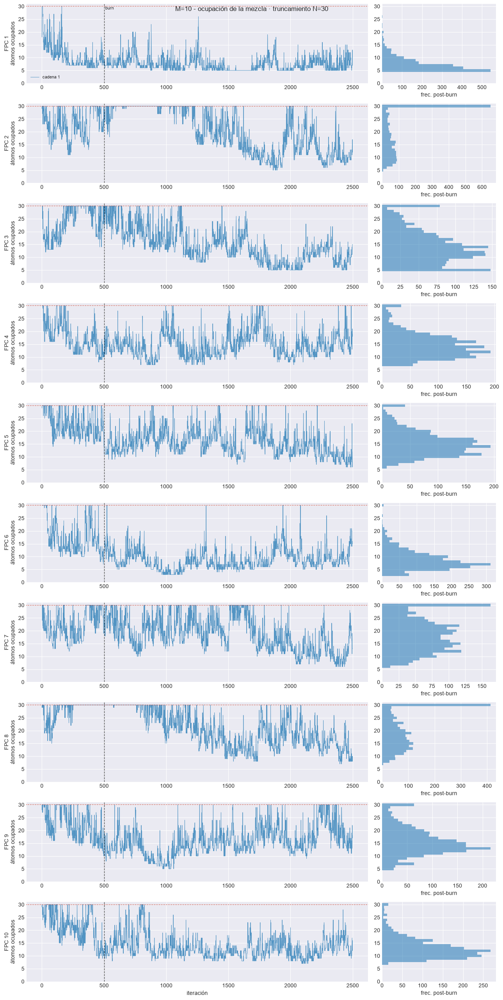

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,10,1,1,7.40,26,17.0,30,False,0.00%
1,10,2,1,20.31,30,30.0,30,True,32.55%
2,10,3,1,14.30,30,30.0,30,True,3.95%
3,10,4,1,14.64,30,30.0,30,True,1.70%
4,10,5,1,15.22,30,30.0,30,True,2.05%
5,10,6,1,8.72,30,20.0,30,True,0.20%
6,10,7,1,18.45,30,30.0,30,True,8.15%
7,10,8,1,20.10,30,30.0,30,True,20.65%
8,10,9,1,15.69,30,30.0,30,True,3.20%
9,10,10,1,13.05,30,28.0,30,True,0.75%


In [6]:
for M in M_OK:
    e = EST[M]
    ocup_df = ocupacion_mezcla(e, M)
    plot_ocupacion_mezcla(e, M, e["paths"]["out_report"] / "41_ocupacion_mezcla.png")
    plt.show()
    display(ocup_df.style.format({"media": "{:.2f}", "p99": "{:.1f}", "frac_en_N": "{:.2%}"})
            .set_caption(f"M={M} - átomos ocupados post-calentamiento"))

### 4.1 Gating: $\psi$, $\alpha$, $\Gamma$

Promedios ponderados por el peso medio de cada átomo, $\bar w_h=\frac1n\sum_i\pi_h(x_i)$,
para que no dependan del etiquetado. **Señal de gating** = átomos efectivos
globales menos por punto (≈ 0 si los pesos son los mismos en todo $x$);
**sd del argumento** = dispersión en $i$ de $\alpha_h-\sum_j\psi_{hj}|x_{ij}-\Gamma_{hj}|$.

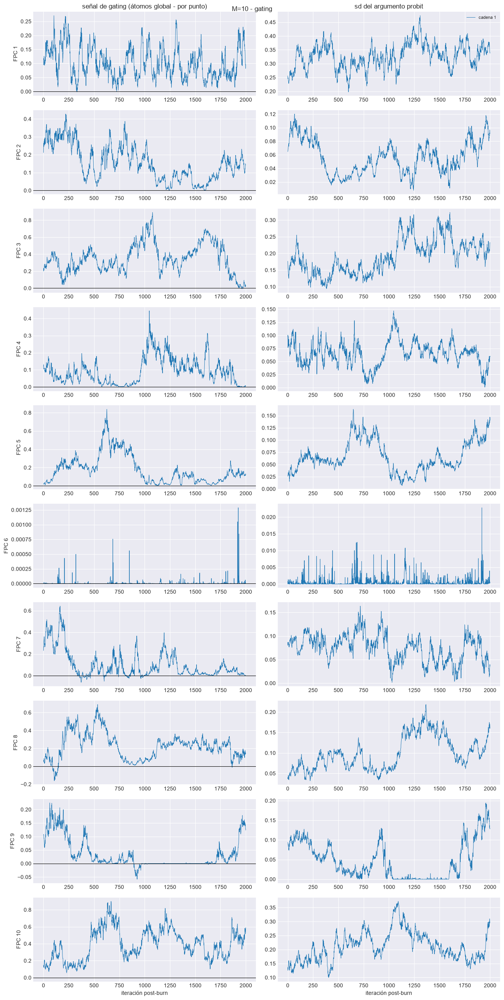

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,10,1,atomos_global,2.546,1,2000,9,9,8.200,nan,False
1,10,1,atomos_punto,2.444,1,2000,8,8,7.760,nan,False
2,10,1,senal_gating,0.102,1,2000,48,48,2.857,nan,False
3,10,1,sd_argumento,0.327,1,2000,19,19,2.393,nan,False
4,10,1,alpha,1.604,1,2000,5,5,3.950,nan,False
5,10,1,psi_0,0.337,1,2000,14,14,1.974,nan,False
6,10,1,psi_1,0.229,1,2000,73,73,2.670,nan,False
7,10,1,psi_2,1.269,1,2000,25,25,0.031,nan,False
8,10,1,psi_3,1.024,1,2000,9,9,8.677,nan,False
9,10,1,psi_4,0.047,1,2000,9,9,2.345,nan,False


In [7]:
_CACHE_GATING = {}      # clave (M, componente, cadena): las series cuestan

for M in M_OK:
    e = EST[M]
    gat, series = diagnostico_gating(e, M, _CACHE_GATING)
    plot_gating(series, e, M, e["paths"]["out_report"] / "49_gating.png")
    plt.show()
    display(gat.style.format({c: "{:.3f}" for c in gat.columns
                              if c.startswith("media_") or c in ("rhat", "geweke_max")}
                             | {"ess_min": "{:.0f}", "ess_mean": "{:.0f}"})
            .set_caption(f"M={M} - gating post-calentamiento"))

## 5. Figuras de convergencia por parámetro

== M=10 ==============================================


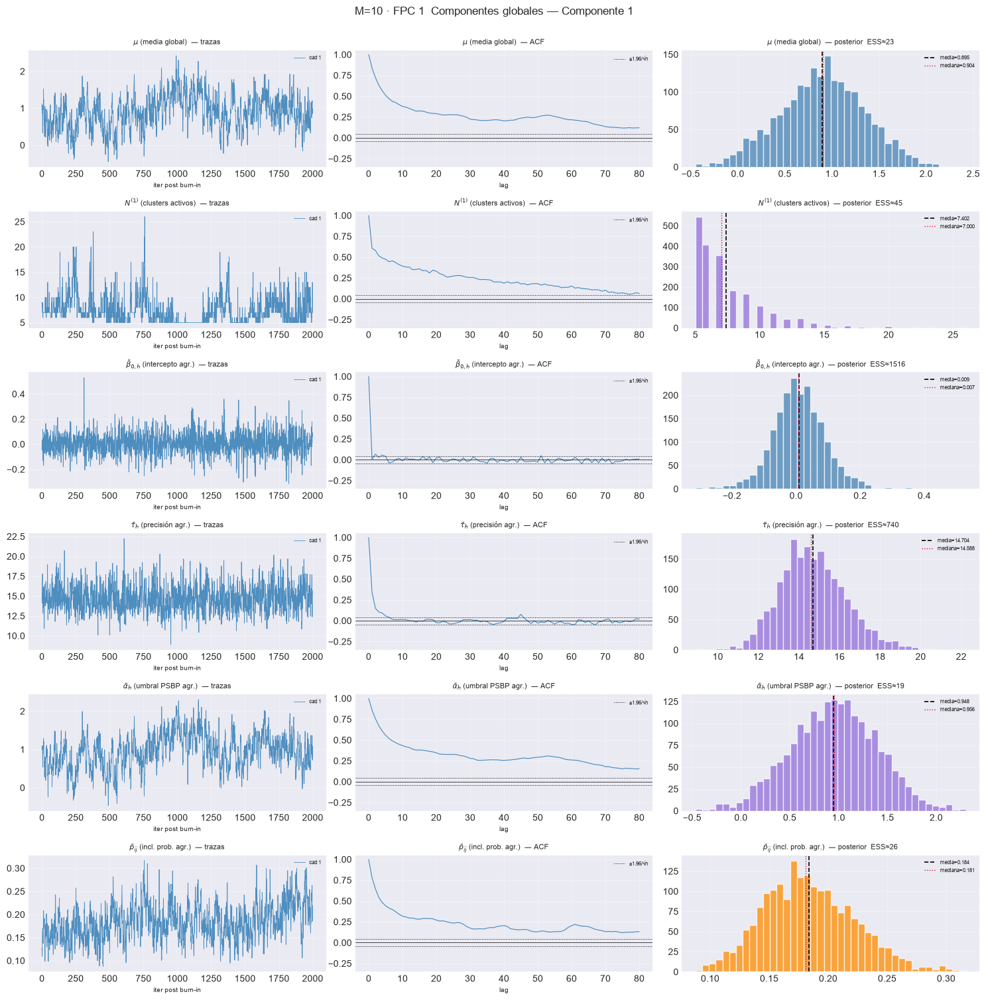

C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:276: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:278: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


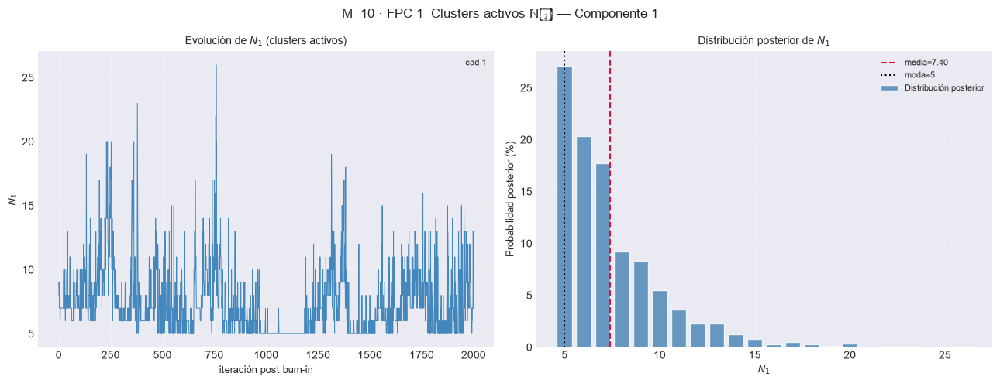

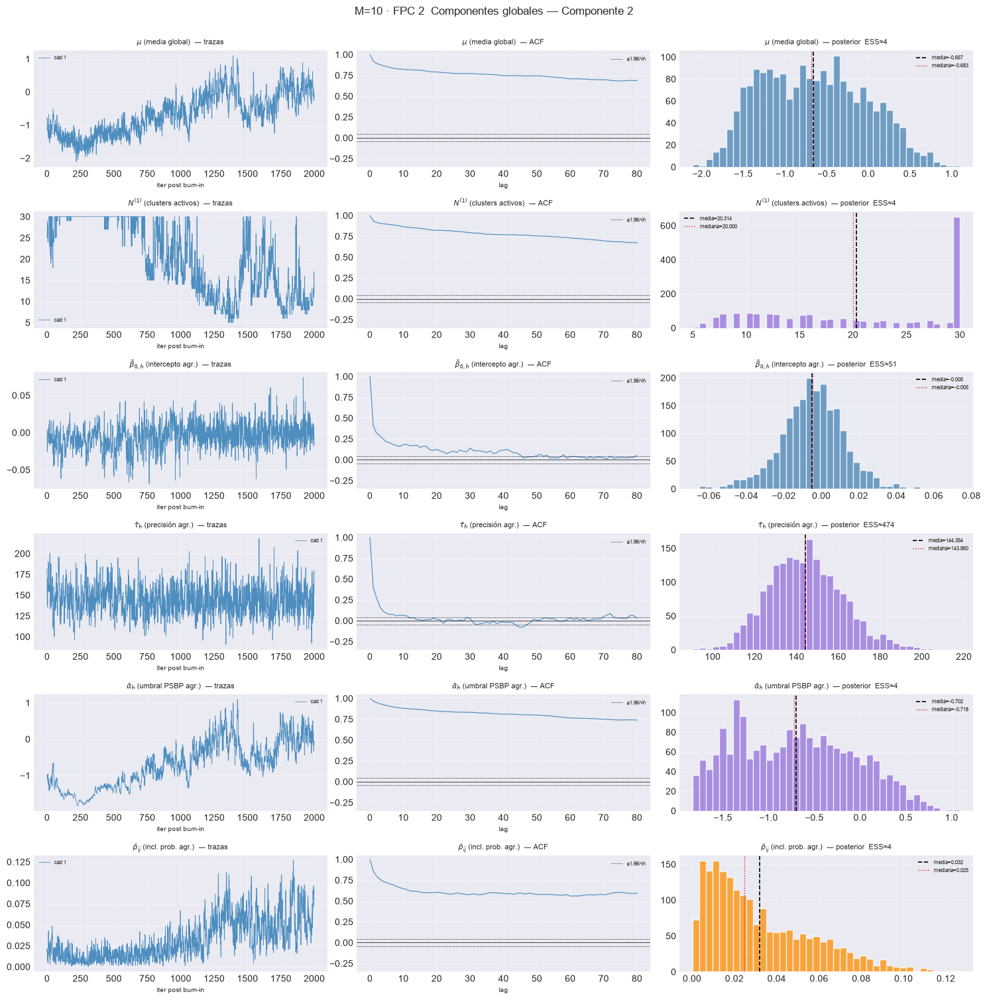

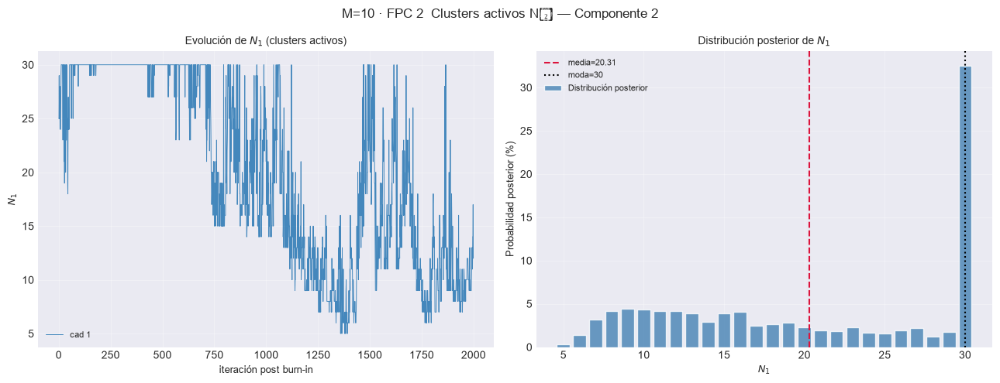

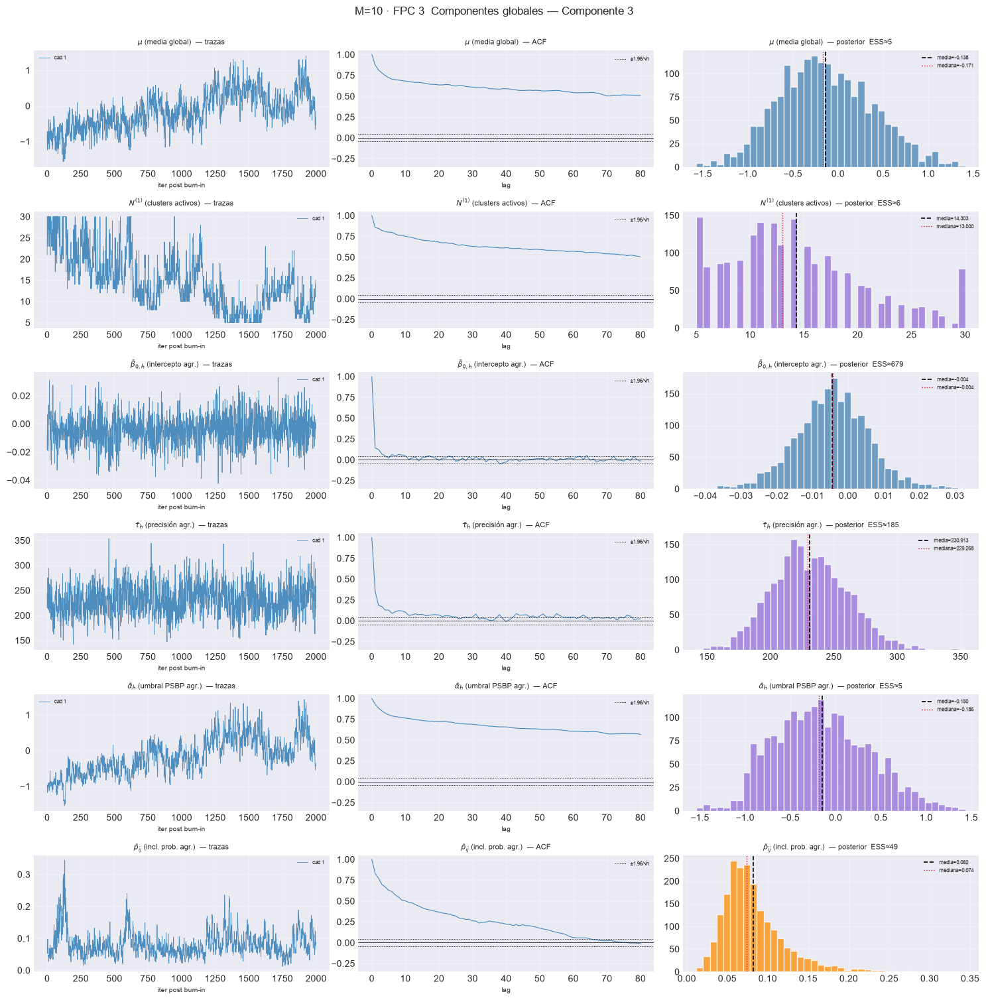

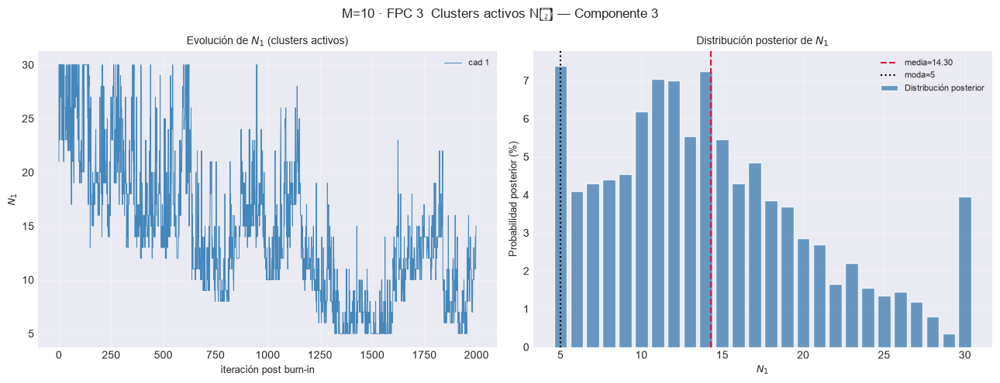

...

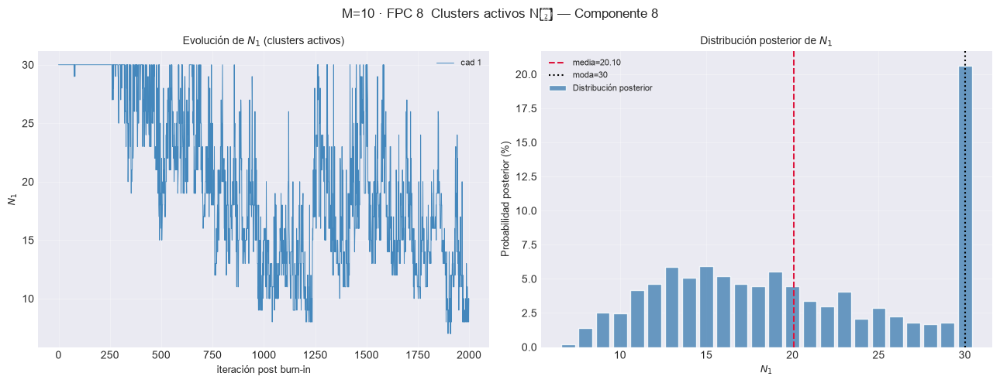

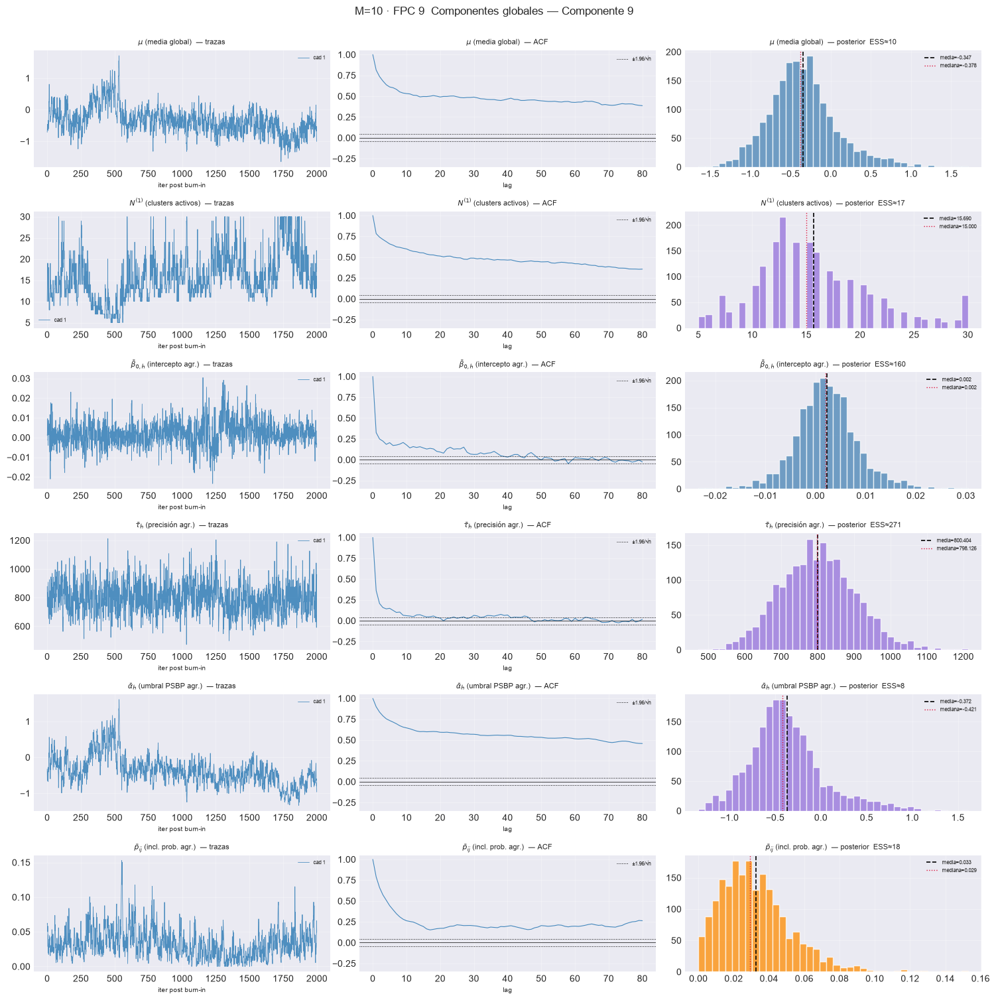

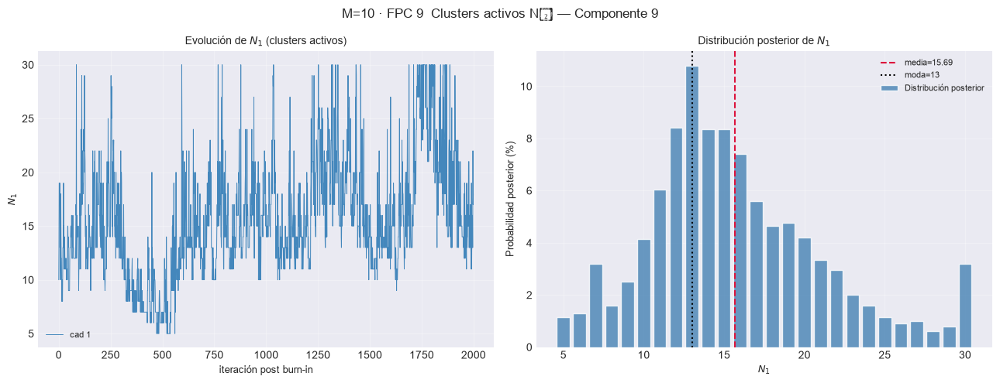

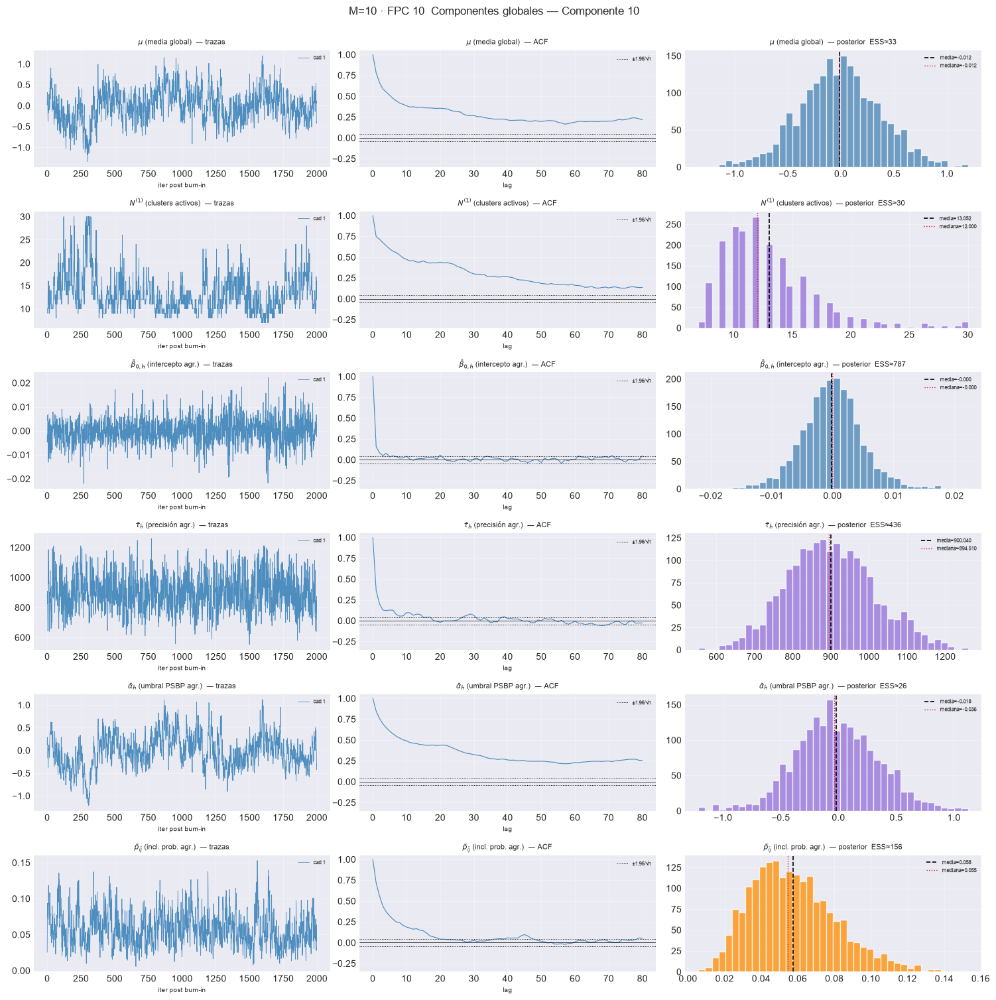

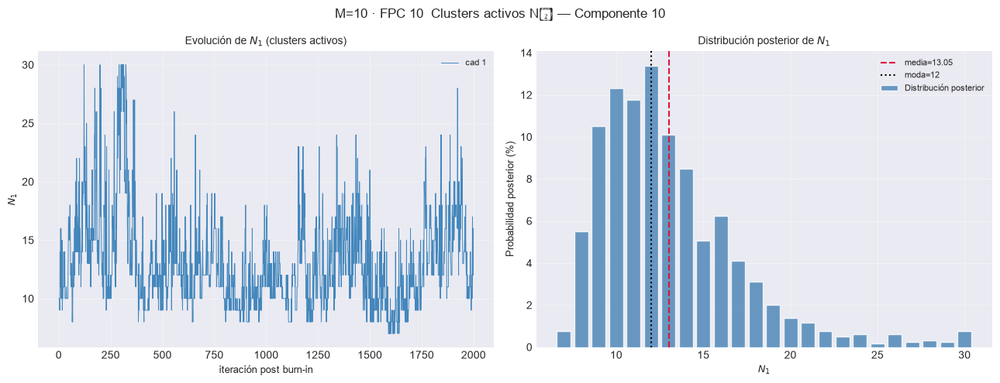

In [8]:
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc = e["component_idx"][k] + 1
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_global_components(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"42_global_k{fpc}.png"))
        plt.show()
        plot_active_clusters(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"43_clusters_k{fpc}.png"))
        plt.show()

== M=10 ==============================================
[plot_convergence_bj[FPC 1]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1439  |G|=1.15  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1538  |G|=1.75  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1617  |G|=1.31  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.73  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1811  |G|=1.35  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=1.00  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=1.41  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1787  |G|=1.05  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1763  |G|=1.34  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1715  |G|=0.06  ✓


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_bj[FPC 1]] listo: 10 pasos en 3.4s  0/10 sin converger


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


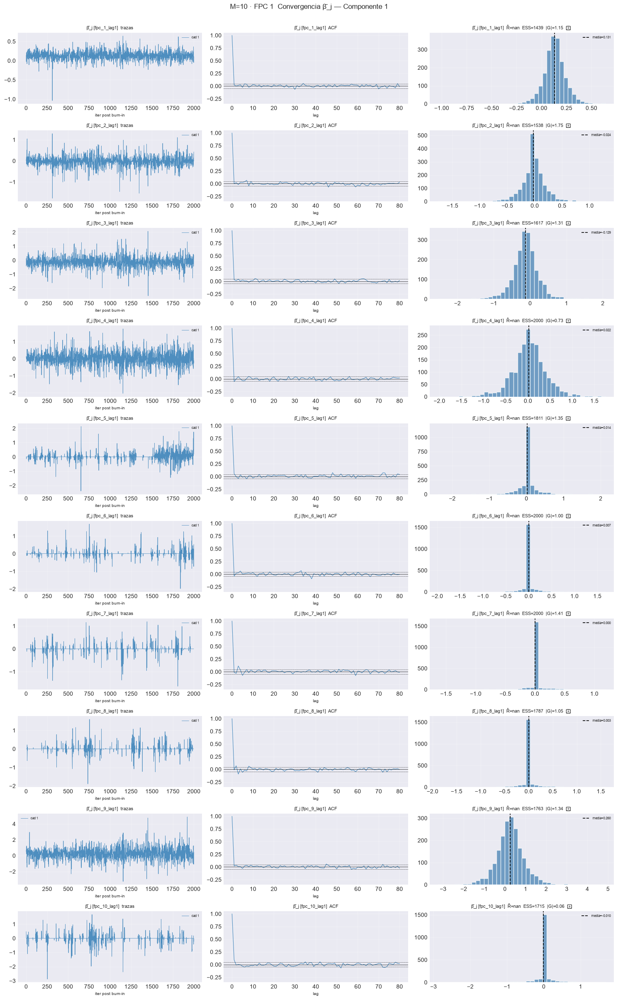

[plot_convergence_pj[FPC 1]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=139  |G|=1.55  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=224  |G|=0.10  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=148  |G|=1.62  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=101  |G|=4.58  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=17  |G|=1.14  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=110  |G|=0.67  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=189  |G|=0.21  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=113  |G|=2.53  ✗


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=58  |G|=2.63  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=113  |G|=0.34  ✓


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_pj[FPC 1]] listo: 10 pasos en 3.2s  4/10 sin converger


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


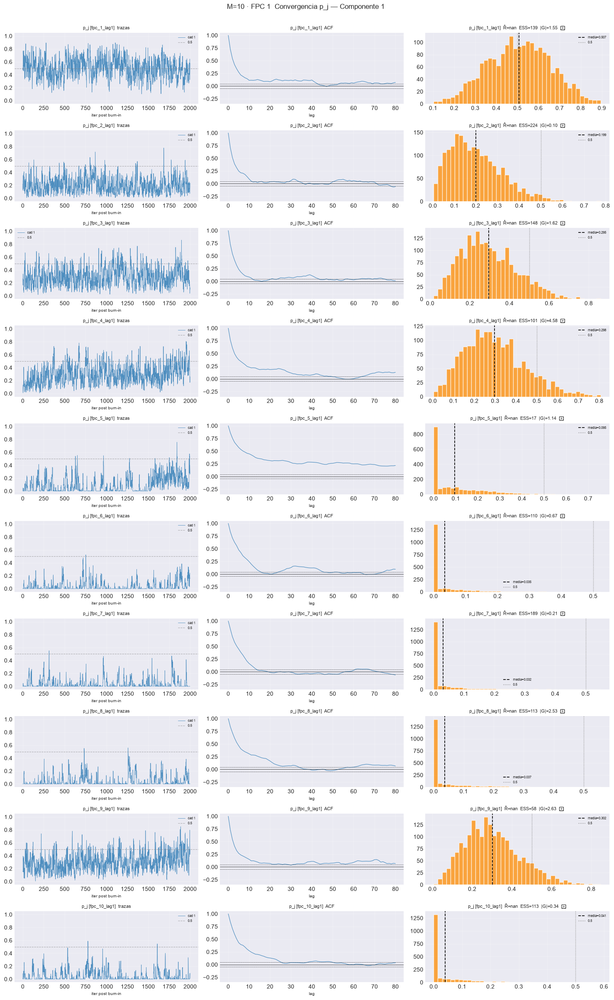

[plot_convergence_bj[FPC 2]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1451  |G|=2.41  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=1.31  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=417  |G|=1.64  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=44  |G|=3.92  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1888  |G|=0.26  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1280  |G|=0.26  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1455  |G|=0.80  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.18  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=0.76  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1759  |G|=0.87  ✓


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_bj[FPC 2]] listo: 10 pasos en 3.4s  2/10 sin converger


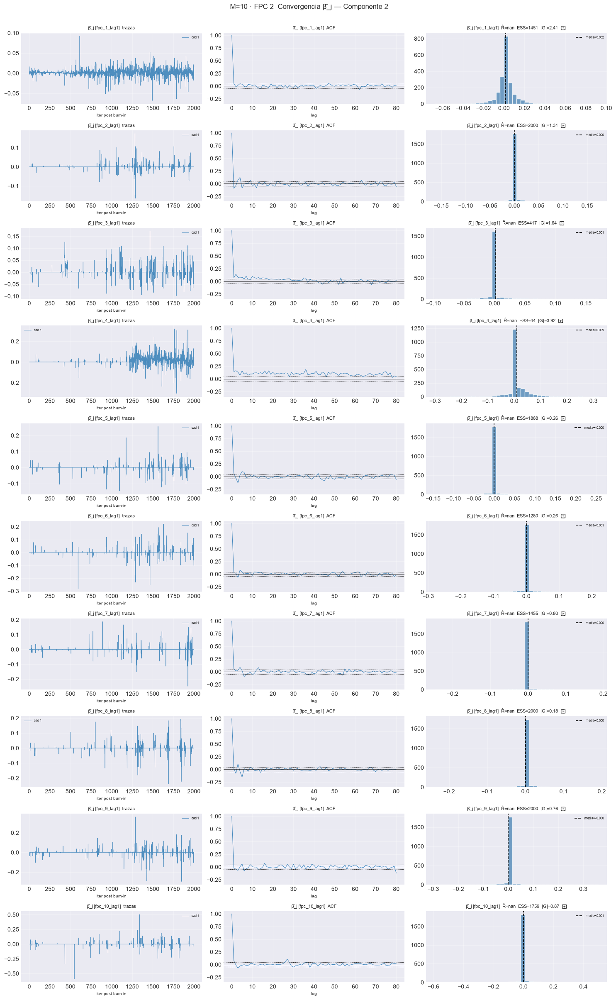

[plot_convergence_pj[FPC 2]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=14  |G|=6.03  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=140  |G|=3.49  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=134  |G|=4.29  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=6  |G|=4.75  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=214  |G|=3.01  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=198  |G|=3.19  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=121  |G|=1.44  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=119  |G|=2.47  ✗


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=230  |G|=2.83  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=291  |G|=0.93  ✓


[plot_convergence_pj[FPC 2]] listo: 10 pasos en 3.1s  8/10 sin converger


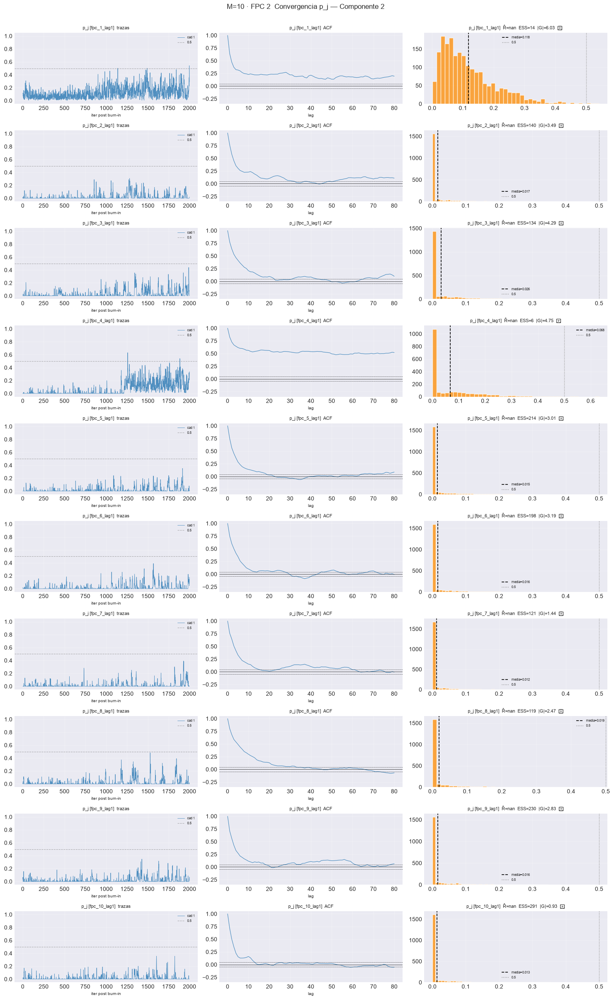

[plot_convergence_bj[FPC 3]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1634  |G|=4.12  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=284  |G|=1.70  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=2000  |G|=0.07  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1571  |G|=2.07  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1547  |G|=2.18  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=0.53  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1897  |G|=0.60  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.75  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=0.15  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1666  |G|=1.22  ✓

[plot_convergence_bj[FPC 3]] listo: 10 pasos en 3.3s  3/10 sin converger


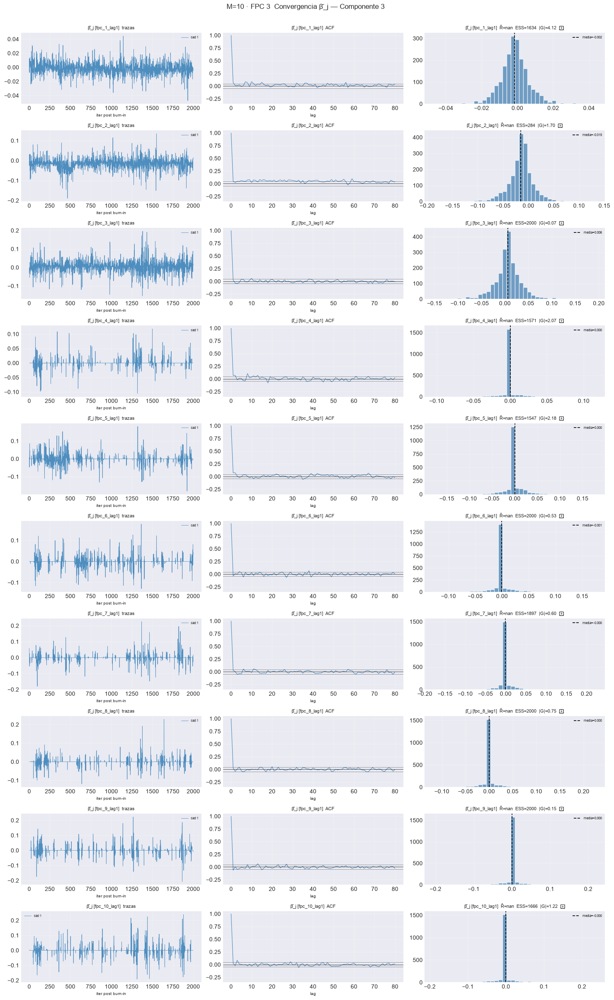

[plot_convergence_pj[FPC 3]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=300  |G|=2.70  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=147  |G|=1.86  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=62  |G|=0.24  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=74  |G|=1.56  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=25  |G|=1.83  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=53  |G|=0.93  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=117  |G|=0.92  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=103  |G|=1.11  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=95  |G|=1.46  ✗

  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=108  |G|=0.80  ✓


[plot_convergence_pj[FPC 3]] listo: 10 pasos en 3.4s  6/10 sin converger


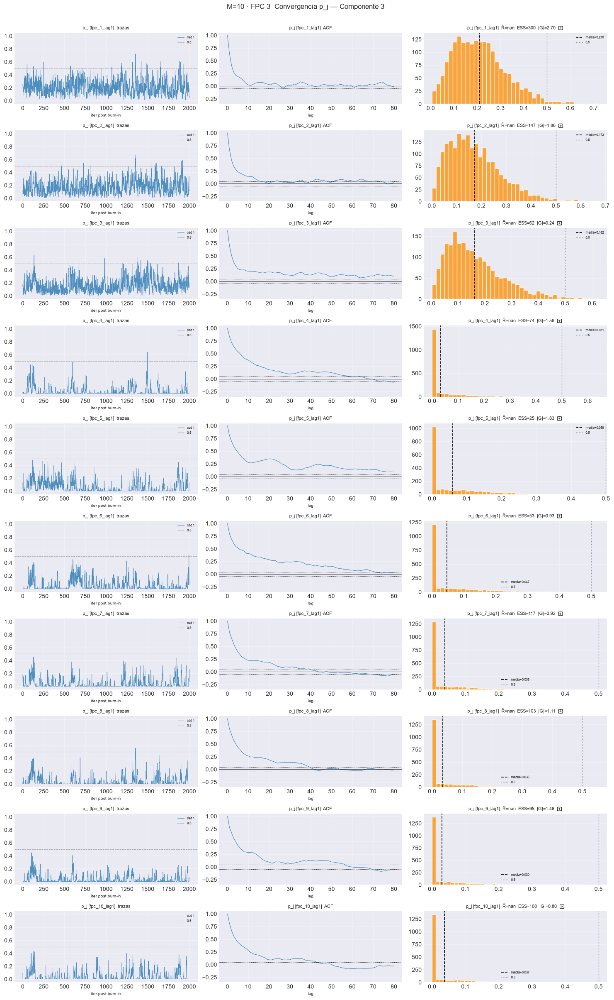

[plot_convergence_bj[FPC 4]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=115  |G|=2.97  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=873  |G|=1.90  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1927  |G|=0.04  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.40  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1952  |G|=0.76  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1833  |G|=1.33  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1798  |G|=1.75  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1588  |G|=0.80  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1538  |G|=0.19  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1865  |G|=0.15  ✓


[plot_convergence_bj[FPC 4]] listo: 10 pasos en 3.4s  1/10 sin converger


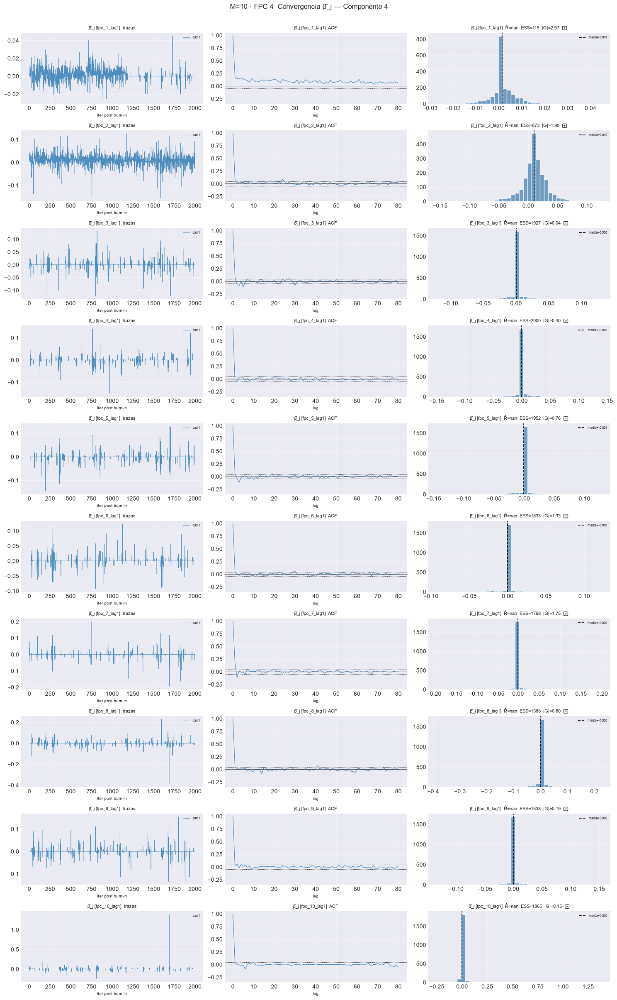

[plot_convergence_pj[FPC 4]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=6  |G|=6.93  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=205  |G|=1.55  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=191  |G|=0.01  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=191  |G|=0.31  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=247  |G|=0.68  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=197  |G|=0.54  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=321  |G|=0.32  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=223  |G|=1.11  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=279  |G|=1.07  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=178  |G|=0.63  ✓

[plot_convergence_pj[FPC 4]] listo: 10 pasos en 3.1s  1/10 sin converger


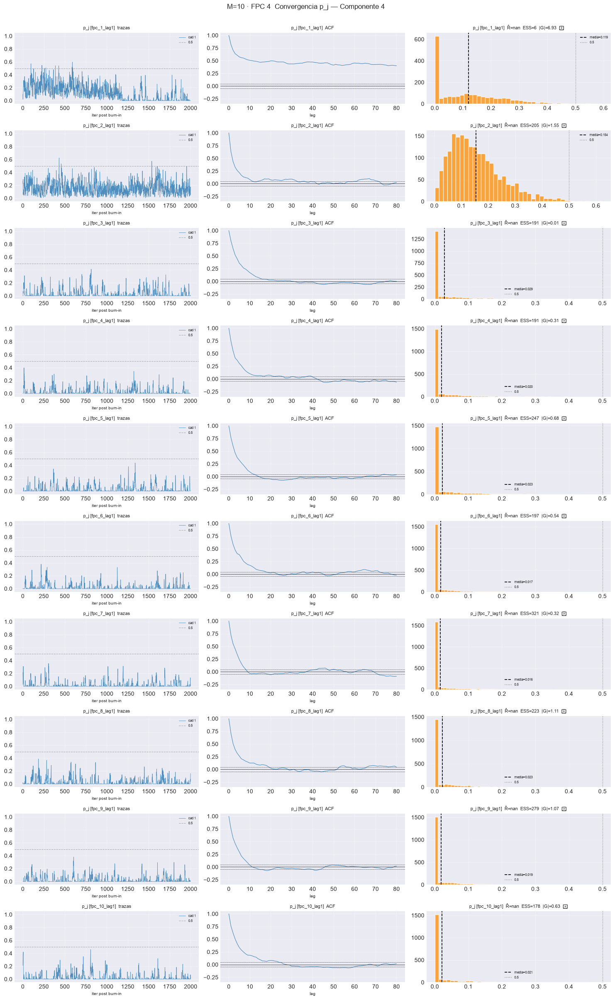

[plot_convergence_bj[FPC 5]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=160  |G|=4.10  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1303  |G|=1.53  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=2000  |G|=1.73  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.56  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1729  |G|=0.35  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=927  |G|=0.35  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1864  |G|=1.26  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.09  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1075  |G|=0.66  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=1.11  ✓

[plot_convergence_bj[FPC 5]] listo: 10 pasos en 3.3s  1/10 sin converger


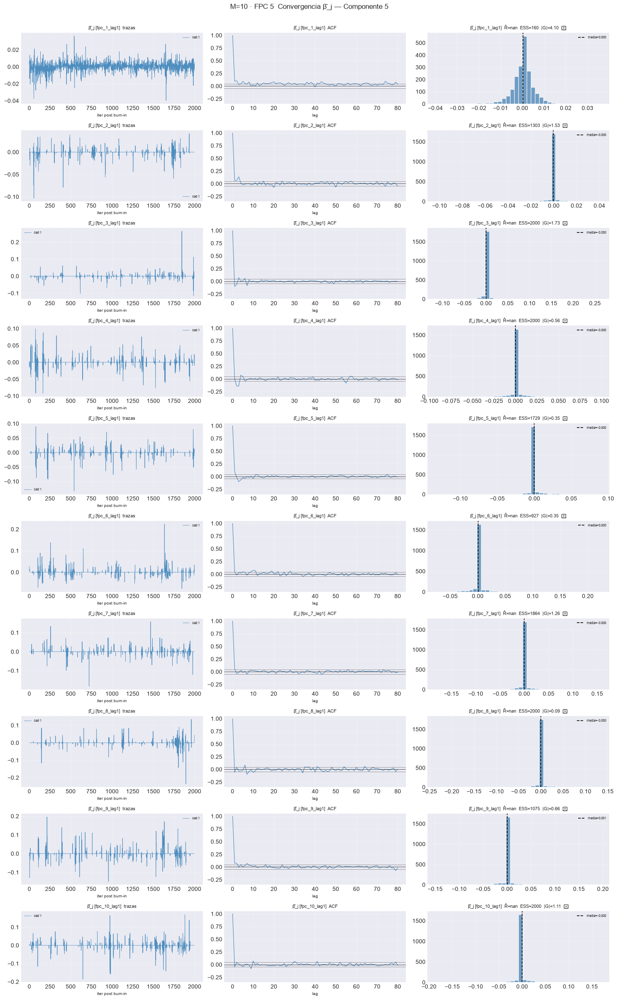

[plot_convergence_pj[FPC 5]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=83  |G|=2.85  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=146  |G|=0.96  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=358  |G|=0.83  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=229  |G|=1.44  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=269  |G|=0.20  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=153  |G|=0.11  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=212  |G|=3.14  ✗


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=64  |G|=1.73  ✗


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=219  |G|=0.62  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=82  |G|=1.80  ✗


[plot_convergence_pj[FPC 5]] listo: 10 pasos en 3.1s  4/10 sin converger


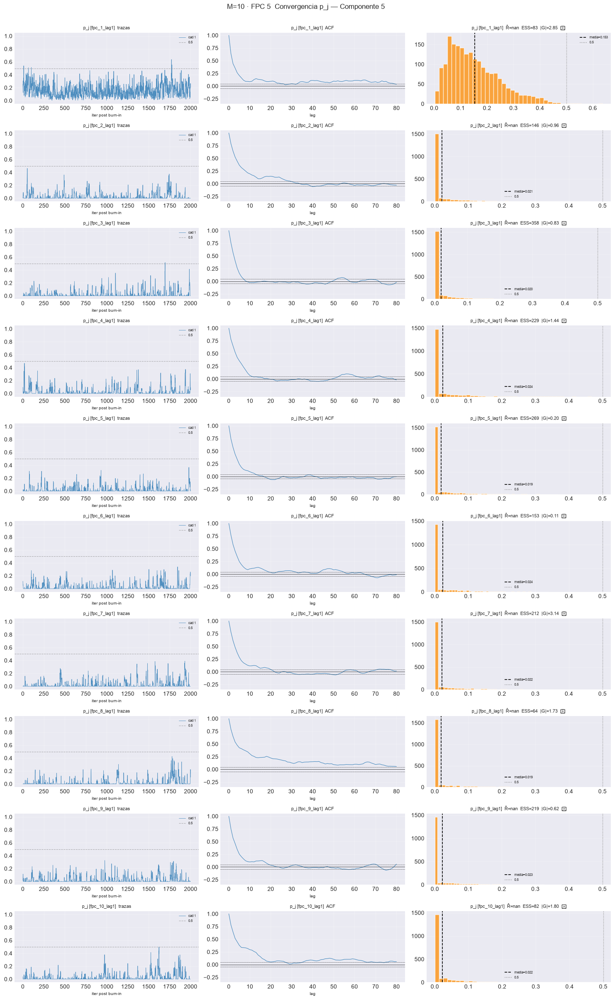

[plot_convergence_bj[FPC 6]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1198  |G|=1.74  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1665  |G|=0.41  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=2000  |G|=0.50  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1897  |G|=0.11  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1674  |G|=0.32  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1576  |G|=0.50  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1223  |G|=0.46  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1647  |G|=0.63  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=1.02  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=1.12  ✓


[plot_convergence_bj[FPC 6]] listo: 10 pasos en 3.4s  0/10 sin converger


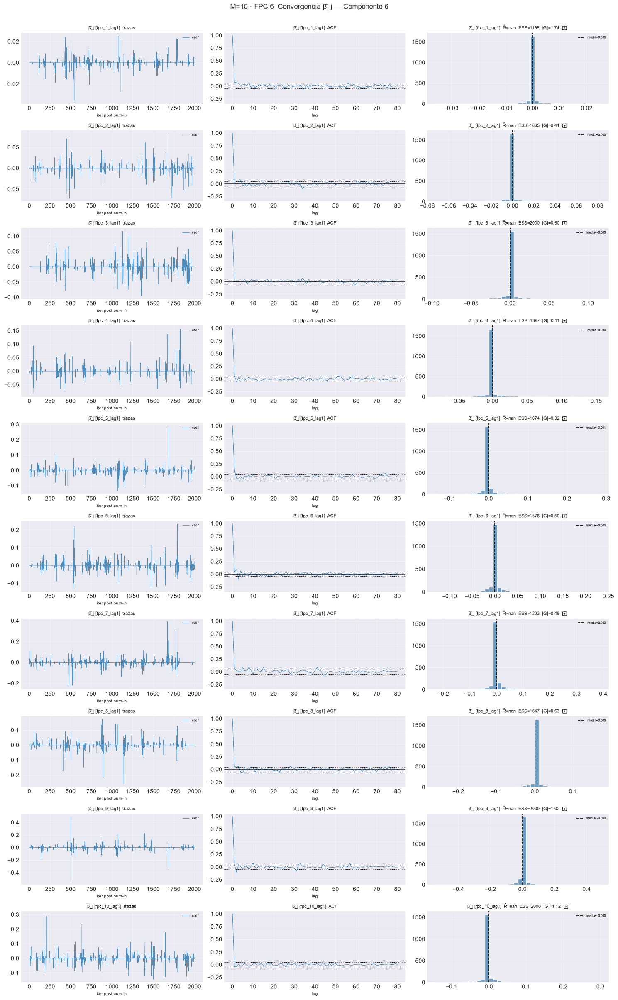

[plot_convergence_pj[FPC 6]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=199  |G|=0.29  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=272  |G|=1.48  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=98  |G|=4.18  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=201  |G|=0.92  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=160  |G|=0.71  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=124  |G|=0.31  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=195  |G|=0.75  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=200  |G|=0.81  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=159  |G|=1.07  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=136  |G|=0.30  ✓

[plot_convergence_pj[FPC 6]] listo: 10 pasos en 3.2s  1/10 sin converger


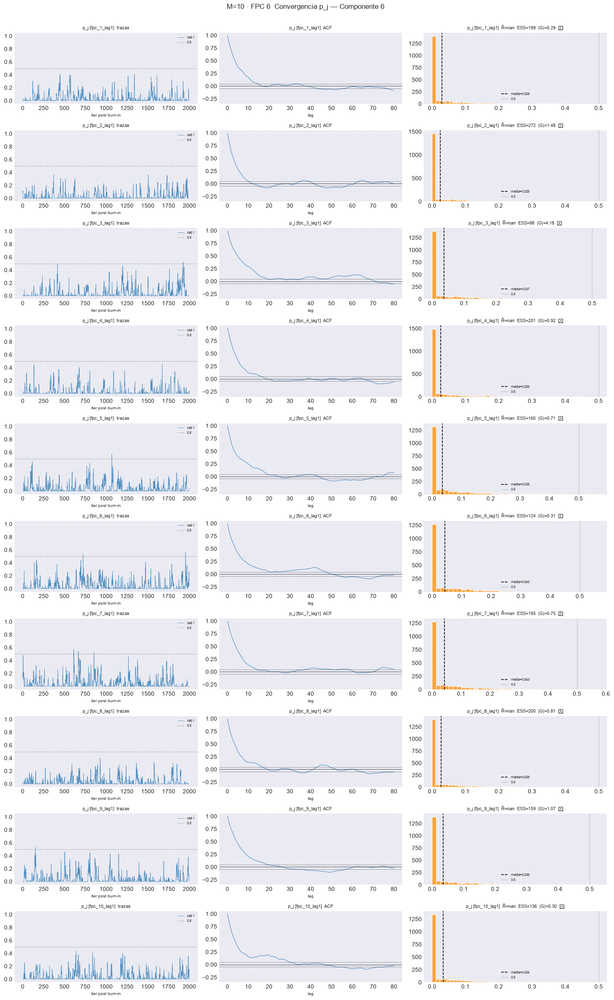

[plot_convergence_bj[FPC 7]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=371  |G|=1.46  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1599  |G|=1.12  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=56  |G|=1.32  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1619  |G|=0.24  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=0.60  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=307  |G|=0.51  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=0.38  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1491  |G|=1.74  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=392  |G|=1.72  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=589  |G|=0.97  ✓

[plot_convergence_bj[FPC 7]] listo: 10 pasos en 3.4s  1/10 sin converger


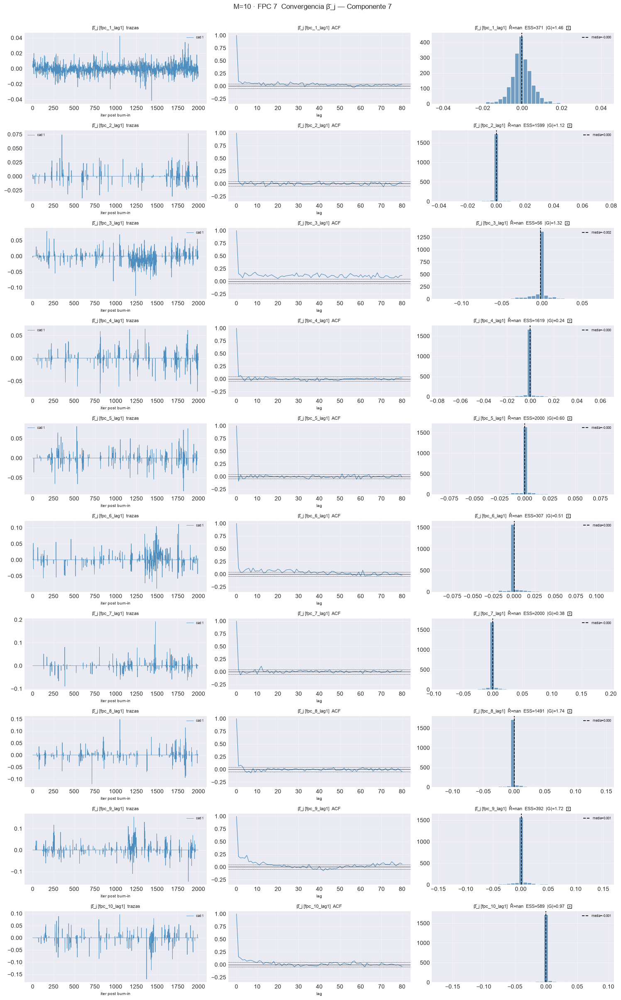

[plot_convergence_pj[FPC 7]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=66  |G|=3.32  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=229  |G|=2.11  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=18  |G|=2.31  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=177  |G|=2.92  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=261  |G|=3.41  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=28  |G|=0.93  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=189  |G|=4.68  ✗


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=167  |G|=0.62  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=62  |G|=1.49  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=213  |G|=0.49  ✓

[plot_convergence_pj[FPC 7]] listo: 10 pasos en 3.2s  8/10 sin converger


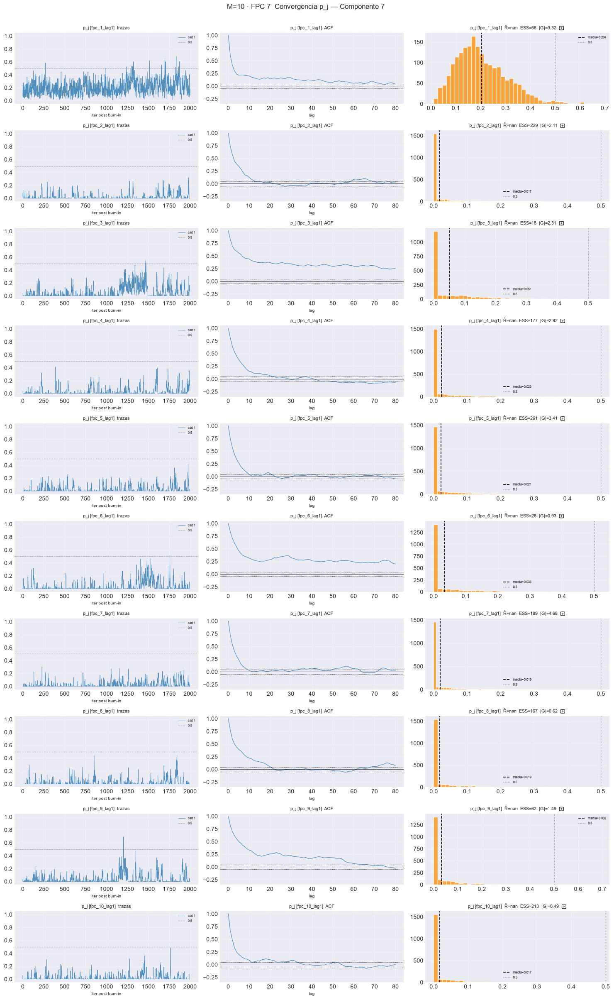

[plot_convergence_bj[FPC 8]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=617  |G|=0.28  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1407  |G|=0.31  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1822  |G|=0.68  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.78  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=0.63  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1525  |G|=0.11  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1376  |G|=0.24  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.58  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=1.52  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=0.63  ✓

[plot_convergence_bj[FPC 8]] listo: 10 pasos en 3.5s  0/10 sin converger


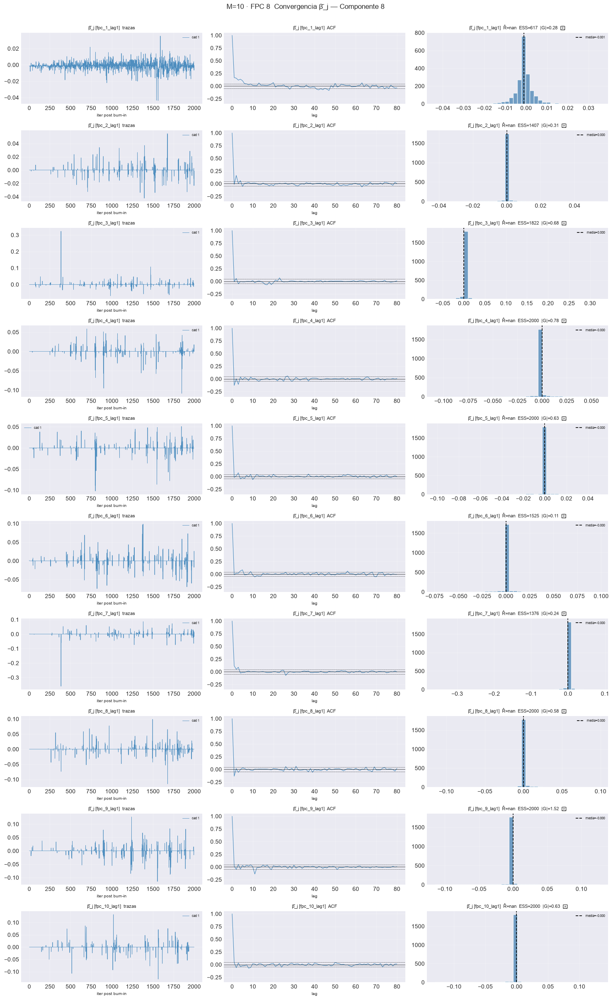

[plot_convergence_pj[FPC 8]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=15  |G|=12.41  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=386  |G|=4.53  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=252  |G|=2.01  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=179  |G|=2.99  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=250  |G|=2.36  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=259  |G|=2.73  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=181  |G|=4.40  ✗


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=283  |G|=5.25  ✗


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=215  |G|=2.90  ✗

  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=310  |G|=3.17  ✗


[plot_convergence_pj[FPC 8]] listo: 10 pasos en 3.1s  10/10 sin converger


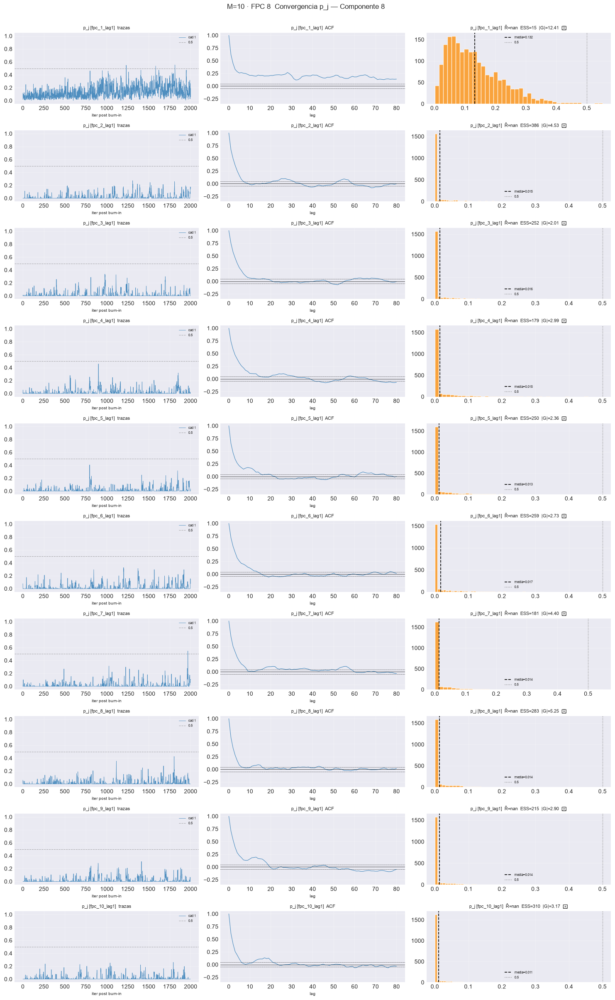

[plot_convergence_bj[FPC 9]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1820  |G|=0.35  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1072  |G|=1.63  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=120  |G|=1.48  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1613  |G|=1.34  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=1.00  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=535  |G|=0.17  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=1.55  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1631  |G|=0.37  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1719  |G|=0.44  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1808  |G|=1.22  ✓

[plot_convergence_bj[FPC 9]] listo: 10 pasos en 3.3s  0/10 sin converger


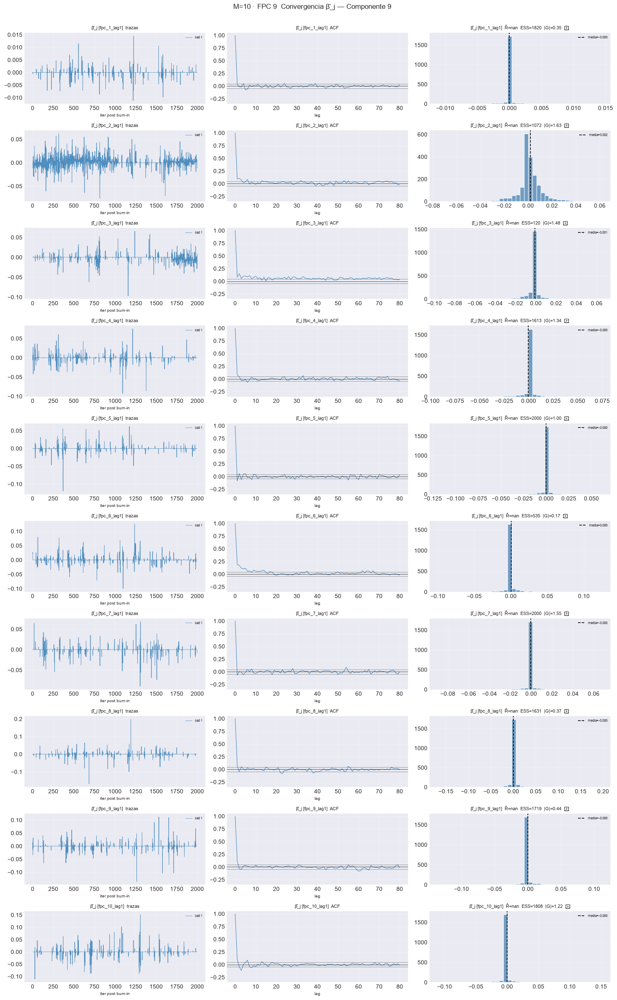

[plot_convergence_pj[FPC 9]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=260  |G|=0.92  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=12  |G|=2.80  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=20  |G|=1.39  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=181  |G|=0.56  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=235  |G|=0.79  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=185  |G|=0.17  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=339  |G|=0.16  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=306  |G|=1.02  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=274  |G|=0.17  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=233  |G|=1.01  ✓

[plot_convergence_pj[FPC 9]] listo: 10 pasos en 3.1s  2/10 sin converger


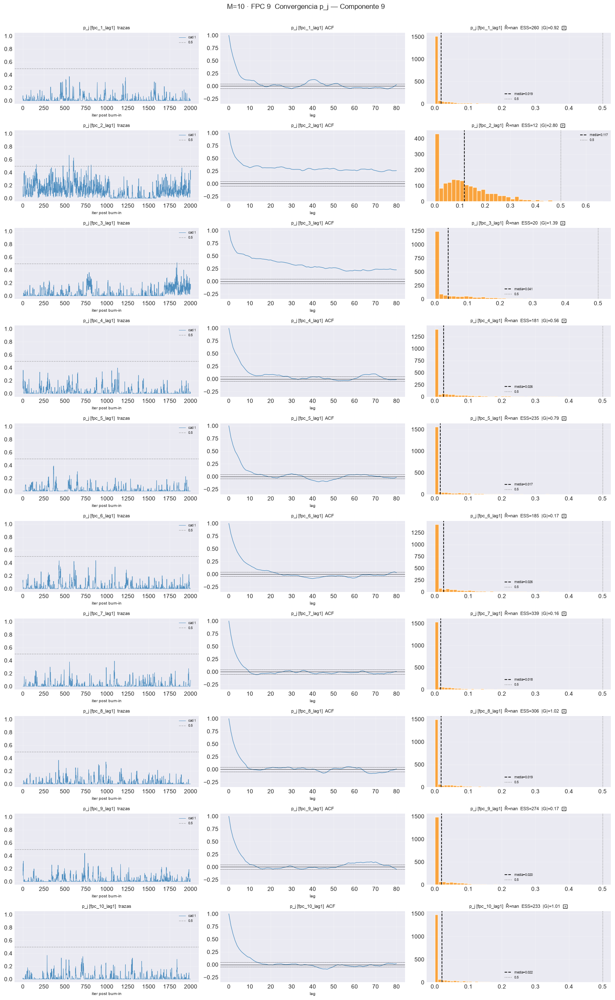

[plot_convergence_bj[FPC 10]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1087  |G|=4.60  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=2000  |G|=0.22  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1623  |G|=0.42  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.42  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=1.10  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1840  |G|=0.56  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1519  |G|=1.51  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1172  |G|=0.23  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=954  |G|=0.15  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1581  |G|=0.26  ✓


[plot_convergence_bj[FPC 10]] listo: 10 pasos en 3.3s  1/10 sin converger


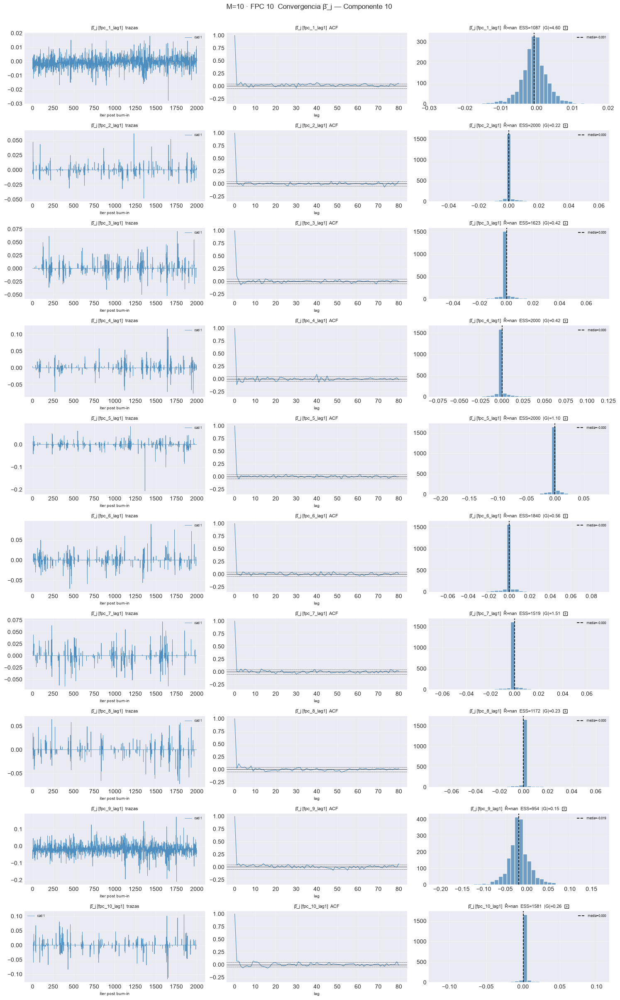

[plot_convergence_pj[FPC 10]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=103  |G|=1.91  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=278  |G|=0.51  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=214  |G|=0.51  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=220  |G|=1.27  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=200  |G|=1.31  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=131  |G|=1.79  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=197  |G|=0.69  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=212  |G|=0.87  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=350  |G|=1.18  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=196  |G|=1.61  ✓

[plot_convergence_pj[FPC 10]] listo: 10 pasos en 3.2s  0/10 sin converger


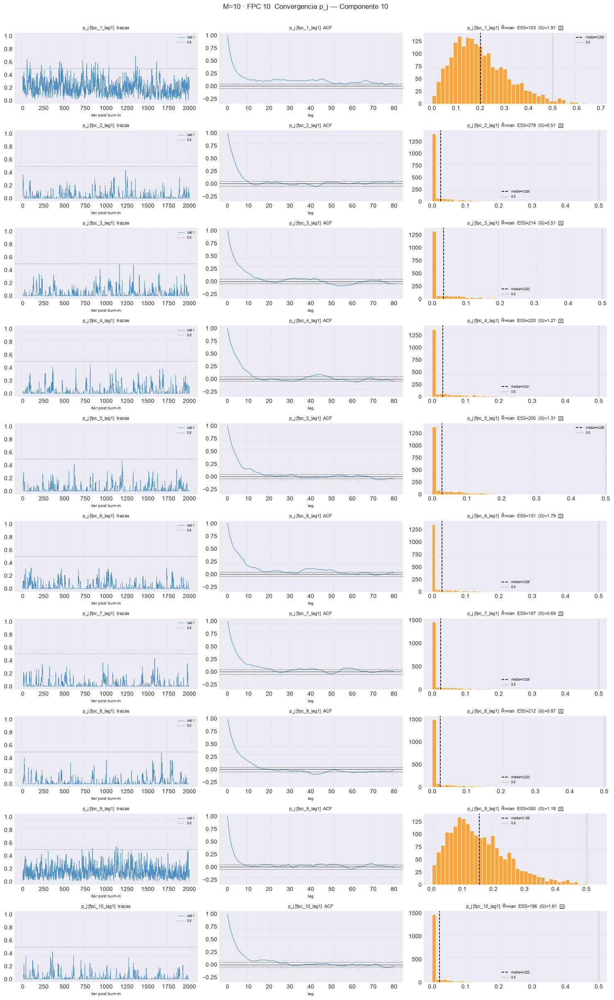

In [9]:
# Traza | ACF | posterior con las métricas anotadas; beta_j va promediado sobre
# átomos (invariante a la permutación de etiquetas). verbose=True saca
# Rhat/ESS/Geweke por covariable a la consola.
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc  = e["component_idx"][k] + 1
        feat = e["models_chains"][k][0].feature_names_
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_convergence_bj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"44_conv_bj_k{fpc}.png"), verbose=True)
        plt.show()
        plot_convergence_pj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"45_conv_pj_k{fpc}.png"), verbose=True)
        plt.show()

## 6. Probabilidades posteriores de inclusión

Tercer eje del diseño (`docs §03_06`): qué variables selecciona el modelo.
Con datos reales no hay estructura verdadera contra la cual contrastar: se reporta
el PIP y su dispersión entre cadenas.

In [10]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} - P(gamma_j = 1 | datos), inclusión global, media entre cadenas +- sd"))

[matriz_pip] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  FPC 1: 1 cadenas, 10 variables, PIP en [0.071, 1.000]


  2/10 (20.0%) t=0.0s eta=0.0s  FPC 2: 1 cadenas, 10 variables, PIP en [0.052, 1.000]


  3/10 (30.0%) t=0.0s eta=0.0s  FPC 3: 1 cadenas, 10 variables, PIP en [0.147, 1.000]


  4/10 (40.0%) t=0.0s eta=0.0s  FPC 4: 1 cadenas, 10 variables, PIP en [0.070, 1.000]


  5/10 (50.0%) t=0.0s eta=0.0s  FPC 5: 1 cadenas, 10 variables, PIP en [0.079, 1.000]


  6/10 (60.0%) t=0.0s eta=0.0s  FPC 6: 1 cadenas, 10 variables, PIP en [0.070, 0.137]


  7/10 (70.0%) t=0.0s eta=0.0s  FPC 7: 1 cadenas, 10 variables, PIP en [0.103, 1.000]


  8/10 (80.0%) t=0.0s eta=0.0s  FPC 8: 1 cadenas, 10 variables, PIP en [0.052, 1.000]


  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 1 cadenas, 10 variables, PIP en [0.082, 0.766]


  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 1 cadenas, 10 variables, PIP en [0.094, 1.000]


[matriz_pip] listo: 10 pasos en 0.0s  tabla 10x20


[M=10] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.627,0.000,1.000,0.000,0.089,0.000,1.000,0.000,1.000,0.000,0.084,0.000,1.000,0.000
fpc_2_lag1,1.000,0.000,0.073,0.000,1.000,0.000,1.000,0.000,0.098,0.000,0.070,0.000,0.103,0.000,0.080,0.000,0.766,0.000,0.113,0.000
fpc_3_lag1,1.000,0.000,0.142,0.000,1.000,0.000,0.123,0.000,0.092,0.000,0.108,0.000,0.297,0.000,0.091,0.000,0.256,0.000,0.157,0.000
fpc_4_lag1,1.000,0.000,0.421,0.000,0.148,0.000,0.097,0.000,0.110,0.000,0.088,0.000,0.109,0.000,0.086,0.000,0.121,0.000,0.146,0.000
fpc_5_lag1,0.385,0.000,0.074,0.000,0.312,0.000,0.092,0.000,0.090,0.000,0.109,0.000,0.123,0.000,0.069,0.000,0.082,0.000,0.122,0.000
fpc_6_lag1,0.097,0.000,0.088,0.000,0.246,0.000,0.081,0.000,0.130,0.000,0.134,0.000,0.185,0.000,0.100,0.000,0.132,0.000,0.125,0.000
fpc_7_lag1,0.071,0.000,0.052,0.000,0.178,0.000,0.070,0.000,0.100,0.000,0.137,0.000,0.114,0.000,0.072,0.000,0.093,0.000,0.106,0.000
fpc_8_lag1,0.101,0.000,0.087,0.000,0.174,0.000,0.104,0.000,0.079,0.000,0.089,0.000,0.111,0.000,0.075,0.000,0.082,0.000,0.103,0.000
fpc_9_lag1,1.000,0.000,0.070,0.000,0.151,0.000,0.095,0.000,0.109,0.000,0.106,0.000,0.179,0.000,0.088,0.000,0.089,0.000,1.000,0.000


## 7. Verificación muestreador ↔ predictor

`inEout` es $E[y\mid x]$ dentro de muestra tal como la calcula MATLAB en cada
iteración. Debe coincidir con lo que el predictor de Python reconstruye de las
mismas trazas: es la única prueba directa de que ambos lados interpretan las
trazas igual. Se corre **en cada $M$** (el contrato depende de $p$).

In [11]:
ok_global = all([verificar_muestreador_predictor(EST[M], CORR_MIN_CONTRATO) for M in M_OK])
print(f"\n{'OK contrato verificado en todo el barrido' if ok_global else 'X el contrato falla'}")

-- M=10 --


  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 2 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 3 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 4 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 5 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 6 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 7 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 8 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 9 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 10 cadena1: corr=1.000000  |dif|max=0.0000

OK contrato verificado en todo el barrido


### 7.1 Paso de $\Gamma$: grilla por predictor y normalización

- cada $\Gamma_{hj}$ muestreado cae **en la grilla de su predictor** `Gstar[:, j]`;
- en cada sorteo, `pm1` es finito y suma 1 (`gamdiagout`).

In [12]:
gamma_df = diagnostico_paso_gamma(EST, M_OK)
display(gamma_df[gamma_df.M == max(M_OK)].style
        .format({"dist_max": "{:.1e}", "err_suma_max": "{:.1e}",
                 "rango_log_mediana": "{:.1f}", "rango_log_max": "{:.1f}"})
        .set_caption(f"M={max(M_OK)} - paso de Gamma, post-burn"))

OK Gamma siempre en su grilla y pm1 finita y normalizada   ·   rango_log mediano 680


,M,FPC,cadena,fuera_de_grilla,dist_max,sorteos,no_finitos,err_suma_max,rango_log_mediana,rango_log_max
0,10,1,1,False,1.2e-07,114788,0,4.4e-16,919.8,4212.1
1,10,2,1,False,1.2e-07,15746,0,4.4e-16,632.6,2216.8
2,10,3,1,False,1.2e-07,46037,0,4.4e-16,1503.5,13376.0
3,10,4,1,False,1.2e-07,22914,0,4.4e-16,489.6,4045.9
4,10,5,1,False,1.2e-07,17351,0,4.4e-16,698.3,3670.6
5,10,6,1,False,1.2e-07,16542,0,4.4e-16,0.0,96.8
6,10,7,1,False,1.2e-07,22889,0,4.4e-16,661.0,4618.2
7,10,8,1,False,1.2e-07,12161,0,4.4e-16,1316.4,3796.8
8,10,9,1,False,1.2e-07,15898,0,4.4e-16,97.2,2681.9
9,10,10,1,False,1.2e-07,31218,0,4.4e-16,1982.3,6243.6


## 8. Comparación entre los puntos del barrido

Las cifras son comparables entre $M$: $\hat R$ máx, ESS mín y Geweke máx son el
**peor caso** del punto (no un promedio sobre un número de variables que cambia
con $M$); la ocupación cuenta átomos; el PIP es una proporción en $[0,1]$.

,experiment_id,p_covariables,n_variables_diag,rhat_max,ess_min,geweke_max,n_no_converge,converge,ocupacion_media,ocupacion_max,N_trunc,toca_truncamiento,pip_sd_max,contrato_ok
M,,,,,,,,,,,,,,
10,real_btc_107_v01_m10,10,200,-,6,12.4138,53,False,14.79,30,30,True,0.0000,True


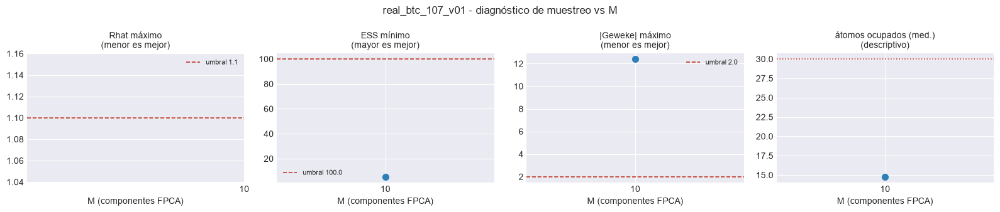

In [13]:
barrido_df = tabla_barrido(EST, M_OK, PATH_BARRIDO)
_fmt = {c: "{:.4f}" for c in ("rhat_max", "geweke_max", "pip_sd_max", "pip_media_activas")
        if c in barrido_df.columns} | {"ess_min": "{:.0f}", "ocupacion_media": "{:.2f}"}
display(barrido_df.style.format(_fmt, na_rep="-")
        .background_gradient(subset=["rhat_max"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption("Diagnóstico de muestreo a lo largo del barrido en M"))

plot_diagnostico_vs_M(barrido_df, EST[M_OK[0]]["res_conv"]["umbrales"], EXPERIMENT_BASE,
                      PATH_BARRIDO / "81_diagnostico_vs_M.png")
plt.show()

FPC,1,2,3,4,5,6,7,8,9,10
M,,,,,,,,,,
10,7.40,20.31,14.30,14.64,15.22,8.72,18.45,20.10,15.69,13.05


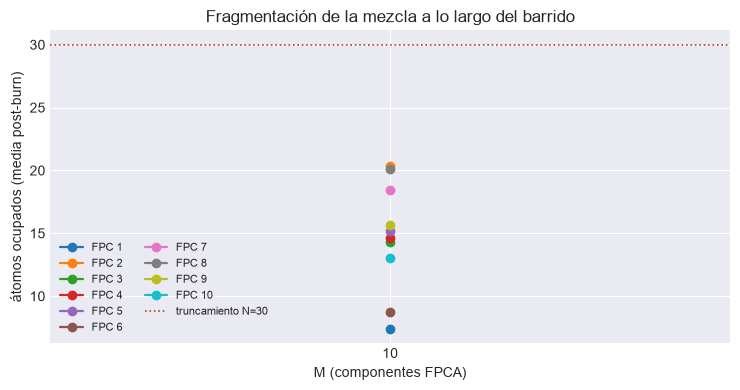

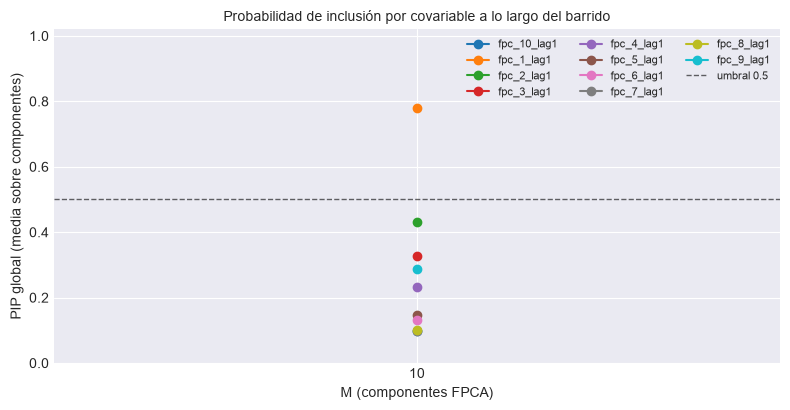

In [14]:
# Ocupación por M y componente: dice si al subir M el modelo parte la mezcla en más átomos.
ocup_todo, piv = ocupacion_barrido(EST, M_OK, PATH_BARRIDO)
display(piv.style.format("{:.2f}", na_rep="-").background_gradient(cmap="RdYlGn_r", axis=None)
        .set_caption("Átomos ocupados (media post-burn) por M y componente FPCA"))
plot_ocupacion_vs_M(piv, int(ocup_todo["N_trunc"].iloc[0]), PATH_BARRIDO / "82_ocupacion_por_M.png")
plt.show()

# PIP por covariable a lo largo del barrido (formato largo).
pip_largo = pip_barrido(EST, M_OK, PATH_BARRIDO)
plot_pip_vs_M(pip_largo, M_OK, PATH_BARRIDO / "83_pip_por_M.png")
plt.show()

In [15]:
veredicto_barrido(barrido_df, EXPERIMENT_BASE, M_FPCA_LIST, M_OK, PATH_BARRIDO)
print("Continuar con 107_04_evaluacion, declarando el mismo M_FPCA_LIST.")

  BARRIDO real_btc_107_v01   ·   M evaluados: [10]
  M=10  p=10  Rhatmax=nan  ESSmin=6  ocup=14.8/30  X NO CONVERGE
------------------------------------------------------------------
X NO convergen: M = [10]. Excluirlos de la comparacion de _04/_05,
  o subir nsim/burn antes de leer su error como efecto de M.
Tablas y figuras cruzadas en C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_btc_107_v01_barrido_M  (archivos 80-83)
Continuar con 107_04_evaluacion, declarando el mismo M_FPCA_LIST.
